This script runs analyses on the data used in Bräcklein et al. 2022 experiments

### Imports

In [1]:
import os
import re  
import math
import pickle
import zipfile
from collections import defaultdict
import sys

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D  

import h5py
from scipy import signal
from scipy.stats import (zscore, ks_2samp, linregress, pearsonr)
from scipy.signal import (convolve, windows, resample)
from scipy.ndimage import gaussian_filter1d

from sklearn.preprocessing import (PolynomialFeatures, StandardScaler)
from sklearn.model_selection import (train_test_split, cross_val_score, KFold)


from scipy.signal import convolve, windows
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from pyglmnet import GLM


import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import PoissonRegressor
from scipy.ndimage import gaussian_filter1d
from sklearn.pipeline import make_pipeline
from scipy.stats import mannwhitneyu
from scipy.interpolate import interp1d
from scipy import stats

sys.path.insert(0, "/Users/nmt121/Desktop/Repositories/Motoneuron_Model")


## Load all sessions

In [2]:
session_files1 = {
    "Day01": ['E3_MB01_Day01High_1.pkl','E3_MB01_Day01High_11.pkl','E3_MB01_Day01High_14.pkl','E3_MB01_Day01High_17.pkl','E3_MB01_Day01High_21.pkl','E3_MB01_Day01High_24.pkl','E3_MB01_Day01High_27.pkl','E3_MB01_Day01High_30.pkl','E3_MB01_Day01High_6.pkl','E3_MB01_Day01High_9.pkl'],
    "Day03": ['E3_MB01_Day03High_11.pkl','E3_MB01_Day03High_14.pkl','E3_MB01_Day03High_18.pkl','E3_MB01_Day03High_21.pkl','E3_MB01_Day03High_23.pkl','E3_MB01_Day03High_26.pkl','E3_MB01_Day03High_29.pkl','E3_MB01_Day03High_3.pkl','E3_MB01_Day03High_4.pkl','E3_MB01_Day03High_9.pkl'],
    "Day04": ['E3_MB01_Day04High_1.pkl','E3_MB01_Day04High_10.pkl','E3_MB01_Day04High_13.pkl','E3_MB01_Day04High_17.pkl','E3_MB01_Day04High_20.pkl','E3_MB01_Day04High_23.pkl','E3_MB01_Day04High_25.pkl','E3_MB01_Day04High_29.pkl','E3_MB01_Day04High_30.pkl','E3_MB01_Day04High_6.pkl','E3_MB01_Day04High_9.pkl'],
    "Day05": ['E3_MB01_Day05High_1.pkl','E3_MB01_Day05High_10.pkl','E3_MB01_Day05High_13.pkl','E3_MB01_Day05High_18.pkl','E3_MB01_Day05High_21.pkl','E3_MB01_Day05High_23.pkl','E3_MB01_Day05High_26.pkl','E3_MB01_Day05High_28.pkl','E3_MB01_Day05High_5.pkl','E3_MB01_Day05High_9.pkl'],
    "Day06": ['E3_MB01_Day06High_10.pkl','E3_MB01_Day06High_14.pkl','E3_MB01_Day06High_18.pkl','E3_MB01_Day06High_21.pkl','E3_MB01_Day06High_22.pkl','E3_MB01_Day06High_26.pkl','E3_MB01_Day06High_3.pkl','E3_MB01_Day06High_30.pkl','E3_MB01_Day06High_5.pkl','E3_MB01_Day06High_9.pkl'],
    "Day07": ['E3_MB01_Day07High_1.pkl','E3_MB01_Day07High_10.pkl','E3_MB01_Day07High_14.pkl','E3_MB01_Day07High_18.pkl','E3_MB01_Day07High_19.pkl','E3_MB01_Day07High_23.pkl','E3_MB01_Day07High_26.pkl','E3_MB01_Day07High_28.pkl','E3_MB01_Day07High_5.pkl','E3_MB01_Day07High_9.pkl'],
    "Day08": ['E3_MB01_Day08High_12.pkl','E3_MB01_Day08High_13.pkl','E3_MB01_Day08High_17.pkl','E3_MB01_Day08High_21.pkl','E3_MB01_Day08High_23.pkl','E3_MB01_Day08High_25.pkl','E3_MB01_Day08High_3.pkl','E3_MB01_Day08High_30.pkl','E3_MB01_Day08High_7.pkl'],
    "Day09": ['E3_MB01_Day09High_1.pkl','E3_MB01_Day09High_13.pkl','E3_MB01_Day09High_15.pkl','E3_MB01_Day09High_18.pkl','E3_MB01_Day09High_23.pkl','E3_MB01_Day09High_26.pkl','E3_MB01_Day09High_27.pkl','E3_MB01_Day09High_4.pkl','E3_MB01_Day09High_8.pkl','E3_MB01_Day09High_9.pkl'],
    "Day10": ['E3_MB01_Day10High_1.pkl','E3_MB01_Day10High_10.pkl','E3_MB01_Day10High_15.pkl','E3_MB01_Day10High_18.pkl','E3_MB01_Day10High_19.pkl','E3_MB01_Day10High_22.pkl','E3_MB01_Day10High_25.pkl','E3_MB01_Day10High_30.pkl','E3_MB01_Day10High_5.pkl','E3_MB01_Day10High_7.pkl'],
    "Day11": ['E3_MB01_Day11High_12.pkl','E3_MB01_Day11High_15.pkl','E3_MB01_Day11High_18.pkl','E3_MB01_Day11High_20.pkl','E3_MB01_Day11High_24.pkl','E3_MB01_Day11High_25.pkl','E3_MB01_Day11High_28.pkl','E3_MB01_Day11High_3.pkl','E3_MB01_Day11High_4.pkl','E3_MB01_Day11High_8.pkl'],
    "Day12": ['E3_MB01_Day12High_12.pkl','E3_MB01_Day12High_15.pkl','E3_MB01_Day12High_17.pkl','E3_MB01_Day12High_2.pkl','E3_MB01_Day12High_20.pkl','E3_MB01_Day12High_24.pkl','E3_MB01_Day12High_25.pkl','E3_MB01_Day12High_28.pkl','E3_MB01_Day12High_4.pkl','E3_MB01_Day12High_7.pkl'],
    "Day13": ['E3_MB01_Day13High_1.pkl','E3_MB01_Day13High_12.pkl','E3_MB01_Day13High_14.pkl','E3_MB01_Day13High_16.pkl','E3_MB01_Day13High_19.pkl','E3_MB01_Day13High_23.pkl','E3_MB01_Day13High_25.pkl','E3_MB01_Day13High_30.pkl','E3_MB01_Day13High_5.pkl','E3_MB01_Day13High_9.pkl'],
    "Day14": ['E3_MB01_Day14High_12.pkl','E3_MB01_Day14High_15.pkl','E3_MB01_Day14High_18.pkl','E3_MB01_Day14High_19.pkl','E3_MB01_Day14High_22.pkl','E3_MB01_Day14High_26.pkl','E3_MB01_Day14High_28.pkl','E3_MB01_Day14High_3.pkl','E3_MB01_Day14High_5.pkl','E3_MB01_Day14High_8.pkl']
}


session_files2 = {
    "Day02": ['E3_MB02_Day02High_10.pkl','E3_MB02_Day02High_14.pkl','E3_MB02_Day02High_18.pkl','E3_MB02_Day02High_2.pkl','E3_MB02_Day02High_20.pkl','E3_MB02_Day02High_24.pkl','E3_MB02_Day02High_27.pkl','E3_MB02_Day02High_29.pkl','E3_MB02_Day02High_6.pkl','E3_MB02_Day02High_9.pkl'],
    "Day03": ['E3_MB02_Day03High_11.pkl','E3_MB02_Day03High_13.pkl','E3_MB02_Day03High_18.pkl','E3_MB02_Day03High_21.pkl','E3_MB02_Day03High_24.pkl','E3_MB02_Day03High_26.pkl','E3_MB02_Day03High_29.pkl','E3_MB02_Day03High_3.pkl','E3_MB02_Day03High_5.pkl','E3_MB02_Day03High_7.pkl'],
    "Day04": ['E3_MB02_Day04High_11.pkl','E3_MB02_Day04High_14.pkl','E3_MB02_Day04High_16.pkl','E3_MB02_Day04High_2.pkl','E3_MB02_Day04High_21.pkl','E3_MB02_Day04High_22.pkl','E3_MB02_Day04High_27.pkl','E3_MB02_Day04High_30.pkl','E3_MB02_Day04High_5.pkl','E3_MB02_Day04High_7.pkl'],
    "Day07": ['E3_MB02_Day07High_1.pkl','E3_MB02_Day07High_12.pkl','E3_MB02_Day07High_13.pkl','E3_MB02_Day07High_16.pkl','E3_MB02_Day07High_19.pkl','E3_MB02_Day07High_24.pkl','E3_MB02_Day07High_27.pkl','E3_MB02_Day07High_30.pkl','E3_MB02_Day07High_4.pkl','E3_MB02_Day07High_9.pkl'],
    "Day13": ['E3_MB02_Day13High_1.pkl','E3_MB02_Day13High_11.pkl','E3_MB02_Day13High_13.pkl','E3_MB02_Day13High_18.pkl','E3_MB02_Day13High_20.pkl','E3_MB02_Day13High_23.pkl','E3_MB02_Day13High_26.pkl','E3_MB02_Day13High_28.pkl','E3_MB02_Day13High_4.pkl','E3_MB02_Day13High_8.pkl']
}


session_files3 = {
    "Day01": ['E3_MB03_Day01High_12.pkl','E3_MB03_Day01High_14.pkl','E3_MB03_Day01High_16.pkl','E3_MB03_Day01High_19.pkl','E3_MB03_Day01High_23.pkl','E3_MB03_Day01High_27.pkl','E3_MB03_Day01High_29.pkl','E3_MB03_Day01High_3.pkl','E3_MB03_Day01High_4.pkl','E3_MB03_Day01High_8.pkl'],
    "Day02": ['E3_MB03_Day02High_12.pkl','E3_MB03_Day02High_15.pkl','E3_MB03_Day02High_17.pkl','E3_MB03_Day02High_19.pkl','E3_MB03_Day02High_2.pkl','E3_MB03_Day02High_24.pkl','E3_MB03_Day02High_26.pkl','E3_MB03_Day02High_29.pkl','E3_MB03_Day02High_6.pkl','E3_MB03_Day02High_8.pkl'],
    "Day03": ['E3_MB03_Day03High_10.pkl','E3_MB03_Day03High_15.pkl','E3_MB03_Day03High_17.pkl','E3_MB03_Day03High_2.pkl','E3_MB03_Day03High_21.pkl','E3_MB03_Day03High_23.pkl','E3_MB03_Day03High_26.pkl','E3_MB03_Day03High_29.pkl','E3_MB03_Day03High_5.pkl','E3_MB03_Day03High_9.pkl'],
    "Day04": ['E3_MB03_Day04High_1.pkl','E3_MB03_Day04High_11.pkl','E3_MB03_Day04High_15.pkl','E3_MB03_Day04High_16.pkl','E3_MB03_Day04High_20.pkl','E3_MB03_Day04High_23.pkl','E3_MB03_Day04High_26.pkl','E3_MB03_Day04High_28.pkl','E3_MB03_Day04High_4.pkl','E3_MB03_Day04High_9.pkl'],
    "Day05": ['E3_MB03_Day05High_12.pkl','E3_MB03_Day05High_15.pkl','E3_MB03_Day05High_17.pkl','E3_MB03_Day05High_20.pkl','E3_MB03_Day05High_22.pkl','E3_MB03_Day05High_26.pkl','E3_MB03_Day05High_29.pkl','E3_MB03_Day05High_3.pkl','E3_MB03_Day05High_4.pkl','E3_MB03_Day05High_7.pkl'],
    "Day07": ['E3_MB03_Day07High_11.pkl','E3_MB03_Day07High_13.pkl','E3_MB03_Day07High_18.pkl','E3_MB03_Day07High_19.pkl','E3_MB03_Day07High_22.pkl','E3_MB03_Day07High_27.pkl','E3_MB03_Day07High_29.pkl','E3_MB03_Day07High_3.pkl','E3_MB03_Day07High_7.pkl'],
    "Day10": ['E3_MB03_Day10High_12.pkl','E3_MB03_Day10High_13.pkl','E3_MB03_Day10High_17.pkl','E3_MB03_Day10High_21.pkl','E3_MB03_Day10High_22.pkl','E3_MB03_Day10High_25.pkl','E3_MB03_Day10High_3.pkl','E3_MB03_Day10High_30.pkl','E3_MB03_Day10High_5.pkl','E3_MB03_Day10High_8.pkl'],
    "Day11": ['E3_MB03_Day11High_10.pkl','E3_MB03_Day11High_14.pkl','E3_MB03_Day11High_18.pkl','E3_MB03_Day11High_20.pkl','E3_MB03_Day11High_23.pkl','E3_MB03_Day11High_26.pkl','E3_MB03_Day11High_3.pkl','E3_MB03_Day11High_30.pkl','E3_MB03_Day11High_6.pkl','E3_MB03_Day11High_9.pkl'],
    "Day12": ['E3_MB03_Day12High_12.pkl','E3_MB03_Day12High_13.pkl','E3_MB03_Day12High_17.pkl','E3_MB03_Day12High_21.pkl','E3_MB03_Day12High_22.pkl','E3_MB03_Day12High_25.pkl','E3_MB03_Day12High_29.pkl','E3_MB03_Day12High_3.pkl','E3_MB03_Day12High_5.pkl','E3_MB03_Day12High_8.pkl'],
    "Day13": ['E3_MB03_Day13High_12.pkl','E3_MB03_Day13High_13.pkl','E3_MB03_Day13High_18.pkl','E3_MB03_Day13High_19.pkl','E3_MB03_Day13High_2.pkl','E3_MB03_Day13High_24.pkl','E3_MB03_Day13High_27.pkl','E3_MB03_Day13High_29.pkl','E3_MB03_Day13High_5.pkl','E3_MB03_Day13High_7.pkl'],
    "Day14": ['E3_MB03_Day14High_12.pkl','E3_MB03_Day14High_13.pkl','E3_MB03_Day14High_16.pkl','E3_MB03_Day14High_21.pkl','E3_MB03_Day14High_24.pkl','E3_MB03_Day14High_26.pkl','E3_MB03_Day14High_29.pkl','E3_MB03_Day14High_3.pkl','E3_MB03_Day14High_4.pkl','E3_MB03_Day14High_8.pkl']
}


session_files4 = {
    "Day01": ['E3_MB04_Day01High_16.pkl','E3_MB04_Day01High_19.pkl','E3_MB04_Day01High_2.pkl','E3_MB04_Day01High_24.pkl','E3_MB04_Day01High_26.pkl','E3_MB04_Day01High_30.pkl','E3_MB04_Day01High_6.pkl','E3_MB04_Day01High_8.pkl'],
    "Day03": ['E3_MB04_Day03High_10.pkl','E3_MB04_Day03High_14.pkl','E3_MB04_Day03High_17.pkl','E3_MB04_Day03High_19.pkl','E3_MB04_Day03High_22.pkl','E3_MB04_Day03High_27.pkl','E3_MB04_Day03High_28.pkl','E3_MB04_Day03High_3.pkl','E3_MB04_Day03High_5.pkl','E3_MB04_Day03High_8.pkl'],
    "Day07": ['E3_MB04_Day07High_15.pkl','E3_MB04_Day07High_29.pkl','E3_MB04_Day07High_6.pkl','E3_MB04_Day07High_8.pkl'],
    "Day08": ['E3_MB04_Day08High_11.pkl','E3_MB04_Day08High_13.pkl','E3_MB04_Day08High_18.pkl','E3_MB04_Day08High_19.pkl','E3_MB04_Day08High_2.pkl','E3_MB04_Day08High_22.pkl','E3_MB04_Day08High_27.pkl','E3_MB04_Day08High_28.pkl','E3_MB04_Day08High_6.pkl','E3_MB04_Day08High_9.pkl'],
    "Day09": ['E3_MB04_Day09High_1.pkl','E3_MB04_Day09High_19.pkl','E3_MB04_Day09High_24.pkl','E3_MB04_Day09High_27.pkl','E3_MB04_Day09High_30.pkl','E3_MB04_Day09High_6.pkl'],
    "Day10": ['E3_MB04_Day10High_11.pkl','E3_MB04_Day10High_15.pkl','E3_MB04_Day10High_17.pkl','E3_MB04_Day10High_2.pkl','E3_MB04_Day10High_21.pkl','E3_MB04_Day10High_22.pkl','E3_MB04_Day10High_26.pkl','E3_MB04_Day10High_28.pkl','E3_MB04_Day10High_4.pkl','E3_MB04_Day10High_9.pkl'],
    "Day11": ['E3_MB04_Day11High_10.pkl','E3_MB04_Day11High_14.pkl','E3_MB04_Day11High_16.pkl','E3_MB04_Day11High_2.pkl','E3_MB04_Day11High_21.pkl','E3_MB04_Day11High_23.pkl','E3_MB04_Day11High_27.pkl','E3_MB04_Day11High_28.pkl','E3_MB04_Day11High_4.pkl','E3_MB04_Day11High_9.pkl'],
    "Day12": ['E3_MB04_Day12High_2.pkl','E3_MB04_Day12High_5.pkl','E3_MB04_Day12High_9.pkl','E3_MB04_Day12High_12.pkl','E3_MB04_Day12High_14.pkl','E3_MB04_Day12High_18.pkl','E3_MB04_Day12High_19.pkl','E3_MB04_Day12High_23.pkl','E3_MB04_Day12High_26.pkl','E3_MB04_Day12High_29.pkl'],
    "Day13": ['E3_MB04_Day13High_3.pkl','E3_MB04_Day13High_4.pkl','E3_MB04_Day13High_8.pkl','E3_MB04_Day13High_12.pkl','E3_MB04_Day13High_14.pkl','E3_MB04_Day13High_18.pkl','E3_MB04_Day13High_19.pkl','E3_MB04_Day13High_24.pkl','E3_MB04_Day13High_27.pkl','E3_MB04_Day13High_30.pkl'],
    "Day14": ['E3_MB04_Day14High_3.pkl','E3_MB04_Day14High_4.pkl','E3_MB04_Day14High_8.pkl','E3_MB04_Day14High_11.pkl','E3_MB04_Day14High_13.pkl','E3_MB04_Day14High_18.pkl','E3_MB04_Day14High_21.pkl','E3_MB04_Day14High_25.pkl','E3_MB04_Day14High_28.pkl']
}


session_files6 = {
    "Day01": ['E3_MB06_Day01High_10.pkl','E3_MB06_Day01High_13.pkl','E3_MB06_Day01High_16.pkl','E3_MB06_Day01High_2.pkl','E3_MB06_Day01High_21.pkl','E3_MB06_Day01High_22.pkl','E3_MB06_Day01High_27.pkl','E3_MB06_Day01High_28.pkl','E3_MB06_Day01High_6.pkl','E3_MB06_Day01High_7.pkl'],
    "Day03": ['E3_MB06_Day03High_1.pkl','E3_MB06_Day03High_10.pkl','E3_MB06_Day03High_14.pkl','E3_MB06_Day03High_17.pkl','E3_MB06_Day03High_21.pkl','E3_MB06_Day03High_22.pkl','E3_MB06_Day03High_27.pkl','E3_MB06_Day03High_29.pkl','E3_MB06_Day03High_6.pkl','E3_MB06_Day03High_8.pkl'],
    "Day04": ['E3_MB06_Day04High_10.pkl','E3_MB06_Day04High_14.pkl','E3_MB06_Day04High_17.pkl','E3_MB06_Day04High_21.pkl','E3_MB06_Day04High_24.pkl','E3_MB06_Day04High_26.pkl','E3_MB06_Day04High_3.pkl','E3_MB06_Day04High_30.pkl','E3_MB06_Day04High_5.pkl','E3_MB06_Day04High_9.pkl'],
    "Day05": ['E3_MB06_Day05High_1.pkl','E3_MB06_Day05High_12.pkl','E3_MB06_Day05High_13.pkl','E3_MB06_Day05High_18.pkl','E3_MB06_Day05High_20.pkl','E3_MB06_Day05High_24.pkl','E3_MB06_Day05High_27.pkl','E3_MB06_Day05High_29.pkl','E3_MB06_Day05High_5.pkl','E3_MB06_Day05High_8.pkl'],
    "Day06": ['E3_MB06_Day06High_1.pkl','E3_MB06_Day06High_12.pkl','E3_MB06_Day06High_14.pkl','E3_MB06_Day06High_18.pkl','E3_MB06_Day06High_20.pkl','E3_MB06_Day06High_23.pkl','E3_MB06_Day06High_27.pkl','E3_MB06_Day06High_29.pkl','E3_MB06_Day06High_4.pkl','E3_MB06_Day06High_9.pkl'],
    "Day07": ['E3_MB06_Day07High_1.pkl','E3_MB06_Day07High_10.pkl','E3_MB06_Day07High_15.pkl','E3_MB06_Day07High_16.pkl','E3_MB06_Day07High_21.pkl','E3_MB06_Day07High_22.pkl','E3_MB06_Day07High_26.pkl','E3_MB06_Day07High_28.pkl','E3_MB06_Day07High_6.pkl','E3_MB06_Day07High_9.pkl'],
    "Day08": ['E3_MB06_Day08High_12.pkl','E3_MB06_Day08High_14.pkl','E3_MB06_Day08High_18.pkl','E3_MB06_Day08High_19.pkl','E3_MB06_Day08High_2.pkl','E3_MB06_Day08High_23.pkl','E3_MB06_Day08High_26.pkl','E3_MB06_Day08High_29.pkl','E3_MB06_Day08High_4.pkl','E3_MB06_Day08High_8.pkl'],
    "Day09": ['E3_MB06_Day09High_1.pkl','E3_MB06_Day09High_11.pkl','E3_MB06_Day09High_14.pkl','E3_MB06_Day09High_16.pkl','E3_MB06_Day09High_20.pkl','E3_MB06_Day09High_22.pkl','E3_MB06_Day09High_27.pkl','E3_MB06_Day09High_30.pkl','E3_MB06_Day09High_6.pkl','E3_MB06_Day09High_8.pkl'],
    "Day10": ['E3_MB06_Day10High_10.pkl','E3_MB06_Day10High_14.pkl','E3_MB06_Day10High_17.pkl','E3_MB06_Day10High_19.pkl','E3_MB06_Day10High_23.pkl','E3_MB06_Day10High_26.pkl','E3_MB06_Day10High_29.pkl','E3_MB06_Day10High_3.pkl','E3_MB06_Day10High_6.pkl','E3_MB06_Day10High_9.pkl'],
    "Day11": ['E3_MB06_Day11High_11.pkl','E3_MB06_Day11High_15.pkl','E3_MB06_Day11High_16.pkl','E3_MB06_Day11High_19.pkl','E3_MB06_Day11High_23.pkl','E3_MB06_Day11High_27.pkl','E3_MB06_Day11High_29.pkl','E3_MB06_Day11High_3.pkl','E3_MB06_Day11High_6.pkl','E3_MB06_Day11High_9.pkl'],
    "Day12": ['E3_MB06_Day12High_10.pkl','E3_MB06_Day12High_14.pkl','E3_MB06_Day12High_16.pkl','E3_MB06_Day12High_21.pkl','E3_MB06_Day12High_24.pkl','E3_MB06_Day12High_25.pkl','E3_MB06_Day12High_3.pkl','E3_MB06_Day12High_30.pkl','E3_MB06_Day12High_5.pkl','E3_MB06_Day12High_9.pkl'],
    "Day13": ['E3_MB06_Day13High_12.pkl','E3_MB06_Day13High_13.pkl','E3_MB06_Day13High_17.pkl','E3_MB06_Day13High_20.pkl','E3_MB06_Day13High_23.pkl','E3_MB06_Day13High_25.pkl','E3_MB06_Day13High_3.pkl','E3_MB06_Day13High_30.pkl','E3_MB06_Day13High_6.pkl','E3_MB06_Day13High_8.pkl'],
    "Day14": ['E3_MB06_Day14High_11.pkl','E3_MB06_Day14High_15.pkl','E3_MB06_Day14High_16.pkl','E3_MB06_Day14High_2.pkl','E3_MB06_Day14High_20.pkl','E3_MB06_Day14High_23.pkl','E3_MB06_Day14High_26.pkl','E3_MB06_Day14High_28.pkl','E3_MB06_Day14High_6.pkl','E3_MB06_Day14High_9.pkl']
}



session_files7 = {
    "Day01": ['E3_MB07_Day01High_10.pkl','E3_MB07_Day01High_13.pkl','E3_MB07_Day01High_17.pkl','E3_MB07_Day01High_2.pkl','E3_MB07_Day01High_21.pkl','E3_MB07_Day01High_24.pkl','E3_MB07_Day01High_26.pkl','E3_MB07_Day01High_28.pkl','E3_MB07_Day01High_5.pkl','E3_MB07_Day01High_9.pkl'],
    "Day02": ['E3_MB07_Day02High_10.pkl','E3_MB07_Day02High_15.pkl','E3_MB07_Day02High_17.pkl','E3_MB07_Day02High_19.pkl','E3_MB07_Day02High_23.pkl','E3_MB07_Day02High_27.pkl','E3_MB07_Day02High_3.pkl','E3_MB07_Day02High_30.pkl','E3_MB07_Day02High_5.pkl','E3_MB07_Day02High_9.pkl'],
    "Day03": ['E3_MB07_Day03High_1.pkl','E3_MB07_Day03High_10.pkl','E3_MB07_Day03High_15.pkl','E3_MB07_Day03High_18.pkl','E3_MB07_Day03High_19.pkl','E3_MB07_Day03High_22.pkl','E3_MB07_Day03High_25.pkl','E3_MB07_Day03High_30.pkl','E3_MB07_Day03High_5.pkl','E3_MB07_Day03High_7.pkl'],
    "Day04": ['E3_MB07_Day04High_11.pkl','E3_MB07_Day04High_15.pkl','E3_MB07_Day04High_18.pkl','E3_MB07_Day04High_21.pkl','E3_MB07_Day04High_23.pkl','E3_MB07_Day04High_27.pkl','E3_MB07_Day04High_28.pkl','E3_MB07_Day04High_3.pkl','E3_MB07_Day04High_6.pkl','E3_MB07_Day04High_7.pkl'],
    "Day05": ['E3_MB07_Day05High_12.pkl','E3_MB07_Day05High_15.pkl','E3_MB07_Day05High_16.pkl','E3_MB07_Day05High_19.pkl','E3_MB07_Day05High_24.pkl','E3_MB07_Day05High_26.pkl','E3_MB07_Day05High_3.pkl','E3_MB07_Day05High_30.pkl','E3_MB07_Day05High_5.pkl','E3_MB07_Day05High_7.pkl'],
    "Day06": ['E3_MB07_Day06High_10.pkl','E3_MB07_Day06High_15.pkl','E3_MB07_Day06High_16.pkl','E3_MB07_Day06High_19.pkl','E3_MB07_Day06High_24.pkl','E3_MB07_Day06High_25.pkl','E3_MB07_Day06High_29.pkl','E3_MB07_Day06High_3.pkl','E3_MB07_Day06High_6.pkl','E3_MB07_Day06High_8.pkl'],
    "Day07": ['E3_MB07_Day07High_1.pkl','E3_MB07_Day07High_10.pkl','E3_MB07_Day07High_13.pkl','E3_MB07_Day07High_18.pkl','E3_MB07_Day07High_20.pkl','E3_MB07_Day07High_24.pkl','E3_MB07_Day07High_26.pkl','E3_MB07_Day07High_29.pkl','E3_MB07_Day07High_6.pkl','E3_MB07_Day07High_9.pkl'],
    "Day08": ['E3_MB07_Day08High_12.pkl','E3_MB07_Day08High_13.pkl','E3_MB07_Day08High_17.pkl','E3_MB07_Day08High_2.pkl','E3_MB07_Day08High_20.pkl','E3_MB07_Day08High_24.pkl','E3_MB07_Day08High_26.pkl','E3_MB07_Day08High_28.pkl','E3_MB07_Day08High_4.pkl','E3_MB07_Day08High_9.pkl'],
    "Day09": ['E3_MB07_Day09High_10.pkl','E3_MB07_Day09High_13.pkl','E3_MB07_Day09High_18.pkl','E3_MB07_Day09High_2.pkl','E3_MB07_Day09High_21.pkl','E3_MB07_Day09High_22.pkl','E3_MB07_Day09High_25.pkl','E3_MB07_Day09High_28.pkl','E3_MB07_Day09High_4.pkl','E3_MB07_Day09High_9.pkl'],
    "Day10": ['E3_MB07_Day10High_10.pkl','E3_MB07_Day10High_13.pkl','E3_MB07_Day10High_16.pkl','E3_MB07_Day10High_2.pkl','E3_MB07_Day10High_21.pkl','E3_MB07_Day10High_22.pkl','E3_MB07_Day10High_26.pkl','E3_MB07_Day10High_29.pkl','E3_MB07_Day10High_4.pkl','E3_MB07_Day10High_9.pkl']
}


# Behavioral analysis

## Plot rasters for each of the trials

In [11]:
# from utils.functions_analysis_online_control_exp.create_rasters import *
# fig = create_raster('/Users/nmt121/Desktop/DATA/S2/', Fsamp=1000, extract_day=extract_day, extract_trial=extract_trial)
# # fig.savefig('/Users/nmt121/Desktop/trial_plot.pdf', dpi=300, bbox_inches='tight')

## Plot force trajectories for every day and every trial

In [ ]:
# from utils.functions_analysis_online_control_exp.force_trajectories import *
# fsamp = 2048  
# highlight_samples = int(3 * fsamp)  #in case one wants to highlight part of the trajectory
# fig = create_force_plots_by_day(directory_path='/Users/nmt121/Desktop/DATA/S2/',fsamp=2048,highlight_samples=1000,extract_day=extract_day,extract_trial=extract_trial)
# # # plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/S7force.pdf', dpi=300, bbox_inches='tight')

### Plot force trajectories from 2 first and 2 last days 

In [12]:
# from utils.functions_analysis_online_control_exp.force_trajectories import *
# plot_force_trials_block(directory_path="/Users/nmt121/Desktop/DATA/S2",save_path="/Users/nmt121/Desktop/S2force.pdf")

## Measure smoothness of the force signal 

/Users/nmt121/Desktop/Repositories/Motoneuron_Model/utils/functions_analysis_online_control_exp/smoothness_force_signal.py:74: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(data=df, x="Group", y="Smoothness", hue="Day",dodge=True, jitter=0.25, alpha=0.5, size=8,ax=ax, palette="tab10", edgecolor='gray', linewidth=0.2)
/Users/nmt121/Desktop/Repositories/Motoneuron_Model/utils/functions_analysis_online_control_exp/smoothness_force_signal.py:89: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["First sessions", "Last sessions"], fontsize=16)


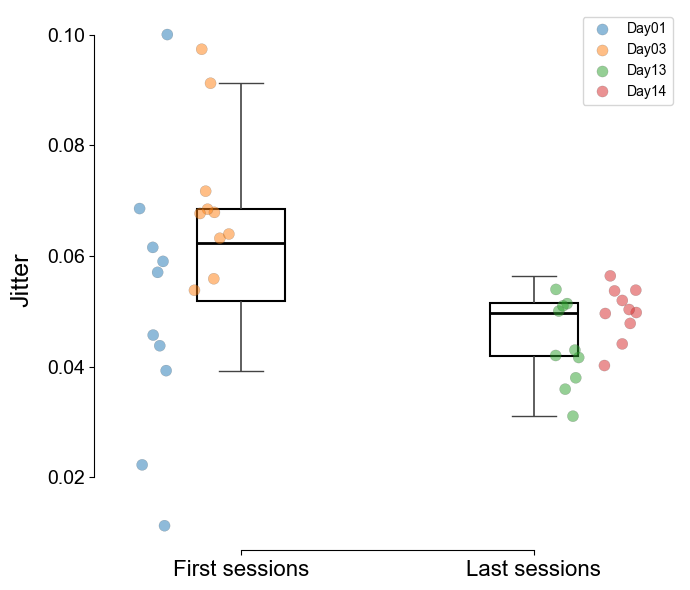

In [42]:
from utils.functions_analysis_online_control_exp.smoothness_force_signal import *
fig = compute_signal_smoothness('/Users/nmt121/Desktop/DATA/S1/', fsamp=2048)
# fig.savefig("/Users/nmt121/Desktop/Figures/learningmetric7_amplitudefft.pdf", dpi=300, bbox_inches='tight')

In [ ]:

# ---------- Helpers (as you had) ----------

def extract_day(filename):
    """
    Extract the day label (e.g., 'Day03') from a filename.
    """
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None  


def extract_trial(filename):
    """
    Extract the trial number from a filename.
    """
    match = re.search(r'_(\d+)[^0-9]', filename)  
    return int(match.group(1)) if match else 0  


def compute_smoothness(force_signal, fsamp, high_freq_threshold=5.0):
    """
    Compute a smoothness metric based on high-frequency content of a force signal.
    Larger values = noisier / less smooth.
    """
    freqs = np.fft.rfftfreq(len(force_signal), d=1/fsamp)
    amp_spectrum = np.abs(np.fft.rfft(force_signal)) / len(force_signal)
    smoothness = np.sum(amp_spectrum[freqs > high_freq_threshold])
    return smoothness


# ---------- A) Trial-level DF for ONE participant (all days) ----------

def collect_smoothness_single_participant(directory_path, fsamp=2048):
    """
    For a single participant: build a DataFrame with one row per trial.

    Columns:
      - day_label   (e.g. 'Day01')
      - day_index   (1, 2, 3, ...)
      - trial       (trial number within day)
      - Smoothness  (high-frequency content metric)
    """
    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

    # group files by day
    files_by_day = {}
    for file in pkl_files:
        day_label = extract_day(file)
        if day_label:
            files_by_day.setdefault(day_label, []).append(file)

    session_days = sorted(files_by_day.keys())
    if len(session_days) == 0:
        raise ValueError("No valid days found in this directory.")

    # map day label -> integer index (1, 2, 3, ...)
    day_to_index = {day_label: i + 1 for i, day_label in enumerate(session_days)}

    rows = []

    for day_label in session_days:
        trial_files = files_by_day[day_label]
        trial_files.sort(key=extract_trial)

        for file_name in trial_files:
            file_path = os.path.join(directory_path, file_name)
            with open(file_path, 'rb') as f:
                data = pickle.load(f)

            force_signal = np.array(data['Force'].tolist())[0]
            smoothness = compute_smoothness(force_signal, fsamp)

            rows.append({
                "day_label": day_label,
                "day_index": day_to_index[day_label],
                "trial": extract_trial(file_name),
                "Smoothness": smoothness
            })

    df = pd.DataFrame(rows)
    return df


# ---------- B) Linear trend per participant: Smoothness ~ day_index ----------

def fit_smoothness_trend_single_participant(directory_path, fsamp=2048):
    """
    For a single participant:
      - build trial-level DataFrame
      - fit linear model: Smoothness ~ day_index
      - print slope and p-value
    """
    df = collect_smoothness_single_participant(directory_path, fsamp)

    model = smf.ols("Smoothness ~ day_index", data=df)
    result = model.fit()

    print("=== Linear model: Smoothness ~ day_index ===")
    print(result.summary())

    slope = result.params["day_index"]
    p_val = result.pvalues["day_index"]

    print(f"\nEffect of day_index (slope): {slope:.4f} (Smoothness units/day)")
    print(f"p-value for day_index: {p_val:.6f}")

    return df, result

participant_dir = "/Users/nmt121/Desktop/DATA/S7/"
fsamp = 2048

# 1) Stats: does jitter decrease across days?
df_S1_jitter, res_S1_jitter = fit_smoothness_trend_single_participant(participant_dir, fsamp)



=== Linear model: Smoothness ~ day_index ===
                            OLS Regression Results                            
Dep. Variable:             Smoothness   R-squared:                       0.104
Model:                            OLS   Adj. R-squared:                  0.095
Method:                 Least Squares   F-statistic:                     11.36
Date:                Thu, 04 Dec 2025   Prob (F-statistic):            0.00107
Time:                        16:05:05   Log-Likelihood:                 251.29
No. Observations:                 100   AIC:                            -498.6
Df Residuals:                      98   BIC:                            -493.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Interce

## Success rate

In [16]:
# from utils.functions_analysis_online_control_exp.success_rate import *
# results = trial_success_rate_per_day('/Users/nmt121/Desktop/DATA/S2/', fsamp=2048)
# for day, stats in results.items():
#     print(f"{day}: {stats['success_rate']:.1f}% ({stats['n_success']}/{stats['n_total']})")

### Stats for differences in success between first two and last two days

In [10]:
# day1 = [40,20,10,0,0,0]
# day2 = [50,60,100,30,70,20]
# day13 = [10,90,100,30,80,52.9]
# day14 = [100,70,100,66.7,70,10]

# first_sessions = np.array(day1 + day2)
# last_sessions  = np.array(day13 + day14)

# print("First sessions mean ± std: %.2f ± %.2f" % (np.mean(first_sessions), np.std(first_sessions)))
# print("Last sessions mean ± std:  %.2f ± %.2f" % (np.mean(last_sessions), np.std(last_sessions)))

# # Independent samples t-test (Welch's)
# t_stat, p_val = stats.ttest_ind(first_sessions, last_sessions, equal_var=False)
# print("Welch t-test: t = %.3f, p = %.4f" % (t_stat, p_val))

# # Mann-Whitney U test (nonparametric alternative)
# u_stat, p_u = stats.mannwhitneyu(first_sessions, last_sessions, alternative="two-sided")
# print("Mann–Whitney U: U = %.3f, p = %.4f" % (u_stat, p_u))

## Find the most representative trial

In [17]:
# from utils.functions_analysis_online_control_exp.choose_representative_force_trial import *
# df, selected = duration_vs_smoothness_scatter_with_median(
#     '/Users/nmt121/Desktop/DATA/S1/', fsamp=2048, high_freq_threshold=5.0,
#     keep_first_last=True, annotate=True,
#     # save_path="/Users/nmt121/Desktop/Figures/dur_vs_smoothness_S7.pdf"
# )

## Compute FFT to see frequency content 

In [ ]:
# from utils.functions_analysis_online_control_exp.FFT_function import *
# results = plot_fft_and_compute_metric_per_trial('/Users/nmt121/Desktop/DATA/S1/', fsamp=2048, fmin=10.0, max_freq=30)

## Plot firing rate state space (in this case for two first and last 2 sessions)

In [19]:
# from utils.functions_analysis_online_control_exp.plot_fr_trajectories import *
# plot_fr_trajectories_block(directory_path="/Users/nmt121/Desktop/DATA/S2",output_path="/Users/nmt121/Desktop/S2_FR_trajectory.pdf",clip_thresh=35)

## Plot trial duration for all trials

In [ ]:
# from utils.functions_analysis_online_control_exp.trial_duration import *
# directory_paths = {"S1": "/Users/nmt121/Desktop/DATA/S1", "S2": "/Users/nmt121/Desktop/DATA/S2","S3": "/Users/nmt121/Desktop/DATA/S3", "S4": "/Users/nmt121/Desktop/DATA/S4", "S6": "/Users/nmt121/Desktop/DATA/S6", "S7": "/Users/nmt121/Desktop/DATA/S7"}
# plot_avg_trial_durations(directory_paths, fsamp=2048,save_path="/Users/nmt121/Desktop/Figures/avg_trial_durations.pdf")


### Plot trial durations from 2 first and 2 last days 

In [39]:
# from utils.functions_analysis_online_control_exp.trial_duration import *
# fig = plot_first_last_two_days_duration_box('/Users/nmt121/Desktop/DATA/S1/', 2048)
# fig.savefig("/Users/nmt121/Desktop/Figures/trial_duration_session1.pdf", dpi=300, bbox_inches='tight')
# fit_duration_trend_single_participant('/Users/nmt121/Desktop/DATA/S7/', 2048)


# Scaling

We need to scale the force to recruit all motoneurons in the simulations and make them match the expected dsitribution

In [21]:
# from utils.functions_analysis_online_control_exp.scale_force_with_mean import *

# scale_and_save_all_trials_mean(
#     directory_path="/Users/nmt121/Desktop/DATA/S2",
#     save_dir="/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S2_alltrials/",
#     target_mean=0.3,
#     plot_examples=True,
#     n_examples=6,
#     overwrite=True,
#     verbose=True
# )

check if the firing rate distributions match

In [ ]:
# # ------------ paths & settings ------------
# exp_folder = "/Users/nmt121/Desktop/DATA/S2"
#     ############################################
#     ############################################
#     ############################################
#     ############################################  
# sim_day1   = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/new/Day1"

# Fs_exp = 2048
# FR_CAP = 80.0
# BINS   = np.linspace(0, 40, 21)

# # ------------ helpers ------------
# def avg_fr_from_spike_times(idx, fs):
#     if idx.size < 2:
#         return None
#     isi = np.diff(idx) / fs
#     m = isi.mean()
#     return None if m <= 0 else 1.0 / m

# def parse_exp_day_trial(fname):
#     # "…Day01…_trial17…" or "…Day1…_17…"
#     mday = re.search(r"Day0*(\d+)", fname)
#     mtr  = re.search(r"(?:_trial|_)(\d+)(?!\d)", fname)
#     if not mday or not mtr:
#         return None
#     return int(mday.group(1)), int(mtr.group(1))

# def _get_MU_array(data):
#     try:
#         MU = np.array(data["MU"])
#         if MU.dtype == object:
#             MU = np.array(data["MU"].tolist())
#         return MU
#     except Exception:
#         return np.array(data["MU"].tolist())

# def _read_jld2_array(h: h5py.File, key: str):
#     if key in h and isinstance(h[key], h5py.Dataset) and h[key].dtype.kind in "biuf":
#         return h[key][:]
#     if f"{key}/value" in h and isinstance(h[f"{key}/value"], h5py.Dataset):
#         d = h[f"{key}/value"]
#         if d.dtype.kind in "biuf":
#             return d[:]
#     if key in h and isinstance(h[key], h5py.Group):
#         g = h[key]
#         if "value" in g and isinstance(g["value"], h5py.Dataset) and g["value"].dtype.kind in "biuf":
#             return g["value"][:]
#     return None

# # ------------ collectors ------------
# def collect_exp_day1_by_trial(exp_dir, fs=2048, fr_cap=80.0):
#     """Experimental FRs grouped by TRIAL, only for Day 1."""
#     by_trial = {}
#     for f in os.listdir(exp_dir):
#         if not f.endswith(".pkl"):
#             continue
#         parsed = parse_exp_day_trial(f)
#         if parsed is None:
#             continue
#         day, trial = parsed
#         ##############
#         ##############
#         ##############
#         if day != 2:
#             continue
#         with open(os.path.join(exp_dir, f), "rb") as fh:
#             data = pickle.load(fh)
#         MU = _get_MU_array(data)

#         frs = []
#         for i in range(MU.shape[0]):
#             idx = np.flatnonzero(MU[i] == 1)
#             fr = avg_fr_from_spike_times(idx, fs)
#             if fr is not None and fr <= fr_cap:
#                 frs.append(fr)
#         if frs:
#             by_trial.setdefault(trial, []).extend(frs)
#     return by_trial

# def collect_sim_day1_by_trial(sim_dir, fr_cap=80.0):

#     """Sim FRs for Day 1: files like force{trial}_firing_rates3.jld2."""
#     by_trial = {}
#     if not os.path.isdir(sim_dir):
#         return by_trial
#     for f in os.listdir(sim_dir):
#         if not (f.endswith(".jld2") or f.endswith(".h5")):
#             continue
    
#     ############################################
#     ############################################
#     ############################################
#     ############################################      
#         m = re.fullmatch(r"force(\d+)_firing_rates\.(?:jld2|h5)", f)
#         if not m:
#             continue
#         trial = int(m.group(1))
#         path = os.path.join(sim_dir, f)
#         try:
#             with h5py.File(path, "r") as h:
#                 rates = _read_jld2_array(h, "avg_rates_per_neuron")
#                 if rates is None:
#                     rates = _read_jld2_array(h, "firing_rates")
#                 if rates is None:
#                     continue
#                 rates = np.asarray(rates, float)
#                 rates = rates[np.isfinite(rates)]
#                 rates = rates[rates <= fr_cap]
#                 if rates.size:
#                     by_trial[trial] = rates
#         except Exception as e:
#             print("could not open", path, "→", e)
#     return by_trial

# # ------------ run ------------
# exp_day1 = collect_exp_day1_by_trial(exp_folder, fs=Fs_exp, fr_cap=FR_CAP)
# sim_day1 = collect_sim_day1_by_trial(sim_day1, fr_cap=FR_CAP)

# trials = sorted(set(exp_day1.keys()) | set(sim_day1.keys()))
# if not trials:
#     raise RuntimeError("No Day 1 trials found in exp or sim folders.")

# # ------------ plot per TRIAL (Day 1) ------------
# cols = 5
# rows = int(np.ceil(len(trials) / cols))
# fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 4*rows))
# axes = np.atleast_1d(axes).ravel()

# for i, tr in enumerate(trials):
#     ax = axes[i]
#     if tr in exp_day1:
#         ax.hist(exp_day1[tr], bins=BINS, density=True, alpha=0.6,
#                 edgecolor="black", linewidth=1.2, label="Experimental")
#     if tr in sim_day1:
#         ax.hist(sim_day1[tr], bins=BINS, density=True, alpha=0.45,
#                 edgecolor="black", linewidth=1.0, label="Simulated")

#     ax.set_title(f"Day 01 — Trial {tr:02d}")
#     ax.set_xlim(0, 40)
#     ax.set_xlabel("Avg firing rate (Hz)")
#     ax.set_ylabel("Density")
#     ax.spines["right"].set_visible(False)
#     ax.spines["top"].set_visible(False)
#     ax.tick_params(axis="both", which="major", labelsize=10)

# # remove empty axes
# for j in range(i+1, len(axes)):
#     fig.delaxes(axes[j])

# # figure-level legend (if anything was plotted)
# for ax in axes:
#     handles, labels = ax.get_legend_handles_labels()
#     if handles:
#         fig.legend(handles, labels, loc="upper right", fontsize=12)
#         break

# plt.tight_layout()
# plt.show()

### scale for the represetative trial

In [22]:
# from utils.functions_analysis_online_control_exp.scale_force_data_with_amplitude_representativetrial import *
# compute_representative_trial(
#     directory_path="/Users/nmt121/Desktop/DATA/S1",
#     save_dir="/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/",
#     file_prefix="force_S111111",
#     target_max=.9,
#     trial_numbers_by_day=[21, 11, 9, 18, 5, 19, 23, 9, 15, 8, 25, 9, 28],
#     plot=True
# )



check if the firing rate distributions match

In [ ]:
# def extract_day(filename):
#     match = re.search(r"(Day\d{2})", filename)
#     return int(match.group(1)[3:]) if match else None

# def extract_trial(filename):
#     match = re.search(r'_(\d+)[^0-9]', filename)
#     return int(match.group(1)) if match else 0

# def compute_avg_firing_rate(spike_times, sampling_rate):
#     if len(spike_times) < 2:
#         return None
#     ISIs = np.diff(spike_times) / sampling_rate
#     return 1 / np.mean(ISIs)

# def load_simulated_rates(jld2_file_paths):
#     sim_rates_by_day = {}
#     for path in jld2_file_paths:
#         day_match = re.search(r'force(\d+)_firing_rates\.jld2', path)
#         if not day_match:
#             continue
#         day = int(day_match.group(1))

#         with h5py.File(path, 'r') as f:
#             if 'avg_rates_per_neuron' in f:
#                 rates = f['avg_rates_per_neuron'][:]
#                 sim_rates_by_day[day] = rates
#                 print(sim_rates_by_day[day])
#             else:
#                 print(f"'avg_rates_per_neuron' not found in {path}")
#     return sim_rates_by_day

# def compute_firing_rate_histograms_with_sim(folder_path, Fsamp, jld2_file_paths):
#     sim_data = load_simulated_rates(jld2_file_paths)
#     pkl_files = sorted(
#         [f for f in os.listdir(folder_path) if f.endswith('.pkl')],
#         key=lambda x: (extract_day(x), extract_trial(x))
#     )
#     day_files = {}
#     for file in pkl_files:
#         day = extract_day(file)
#         if day is not None:
#             day_files.setdefault(day, []).append(file)

#     n_days = len(day_files)
#     n_cols = 4
#     n_rows = int(np.ceil(n_days / n_cols))
#     fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
#     axes = axes.flatten()

#     for i, (day, files) in enumerate(sorted(day_files.items())):
#         all_firing_rates = []
#         for file in files:
#             with open(os.path.join(folder_path, file), 'rb') as f:
#                 data = pickle.load(f)
#             MU_array = np.array(data['MU'])

#             for neuron_idx in range(MU_array.shape[0]):
#                 spike_times = np.where(MU_array[neuron_idx] == 1)[0]
#                 fr = compute_avg_firing_rate(spike_times, Fsamp)
#                 if fr is not None and fr <= 80:
#                     all_firing_rates.append(fr)

#         ax = axes[i]
#         bin_edges = np.linspace(0, 40, 21)

#         ax.hist(all_firing_rates, bins=bin_edges, color='blue', alpha=0.4,
#                 label='Experimental', density=True, edgecolor='black', linewidth=1.2)

#         if day in sim_data:
#             ax.hist(sim_data[day], bins=bin_edges, color='red', alpha=0.4,
#                     label='Simulated', density=True, edgecolor='black', linewidth=1.2)

#         # ax.set_title(f'Day {day}: {len(all_firing_rates)} neurons')  # Title removed
#         ax.set_xlabel('Avg firing rate (Hz)', fontsize=16)
#         ax.set_ylabel('Density', fontsize=16)

#         # Remove legend
#         # ax.legend()

#         # Remove top and right spines
#         ax.spines['right'].set_visible(False)
#         ax.spines['top'].set_visible(False)

#         # Make ticks bigger
#         ax.tick_params(axis='both', which='major', labelsize=16)

#     for j in range(i + 1, len(axes)):
#         fig.delaxes(axes[j])

#     plt.tight_layout()
#     return fig



# folder_path = "/Users/nmt121/Desktop/DATA/S1"
# Fsamp = 2048

# jld2_file_paths = [
    
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force1_firing_rates_last_trial.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force3_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force4_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force5_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force6_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force7_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force8_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force9_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force10_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force11_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force12_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force13_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force14_firing_rates_last_trial.jld2',
    

# ]

# fig = compute_firing_rate_histograms_with_sim(folder_path, Fsamp, jld2_file_paths)
# # plt.savefig('/Users/nmt121/Desktop/Figures/FRdistributions_S1.pdf', dpi=300, bbox_inches='tight')
# plt.show()